# Demo · Control intermedio del día 7

> **Prototipo académico; no apto para diagnóstico ni decisiones clínicas.**

Orden de la demostración (8-10 min). Cada sección es independiente: si el docente pide un
cambio, se edita **la variable en mayúsculas** de esa sección y se vuelve a ejecutar.

1. Lectura de imágenes  2. Distribución por clases  3. Pacientes sin mezclar entre particiones
4. Identificadores  5. Entrenamiento preliminar  6. Cambiar umbral  7. Localizar un falso negativo
8. Alterar una transformación

Requisitos: haber ejecutado antes los notebooks 04 y 05 (PNG, checkpoints e historiales en Drive).

In [1]:
!pip install -q pydicom

In [2]:
# Montar Drive y fijar rutas (las mismas en todos los notebooks)
from google.colab import drive
drive.mount('/content/drive')

import os, sys
BASE    = "/content/drive/MyDrive/Aprendizaje final"
DATA    = f"{BASE}/Csv"
RES     = f"{BASE}/resultados"
SRC     = f"{BASE}/src"
PART    = f"{RES}/particiones"
PNG     = f"{BASE}/procesadas_224"     # recortes preprocesados (no van a Git)
MODELOS = f"{BASE}/modelos"            # checkpoints .pt (no van a Git)
for p in [DATA, RES, SRC, PART]:
    assert os.path.exists(p), f"No existe: {p}"
sys.path.insert(0, SRC)

Mounted at /content/drive


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pydicom, torch
from PIL import Image
import modelo_utils as mu

disp  = pd.read_csv(f"{RES}/lesiones_disponibles.csv")
parts = {s: pd.read_csv(f"{PART}/{s}.csv") for s in ["train", "val", "test"]}
todas = pd.concat([d.assign(split=s) for s, d in parts.items()], ignore_index=True)

## 1. Lectura de imágenes

PatientID DICOM: Mass-Training_P_00004_LEFT_CC_1 | SeriesDescription: cropped images
Tamaño original: (466, 423) uint16 | fotometría: MONOCHROME2


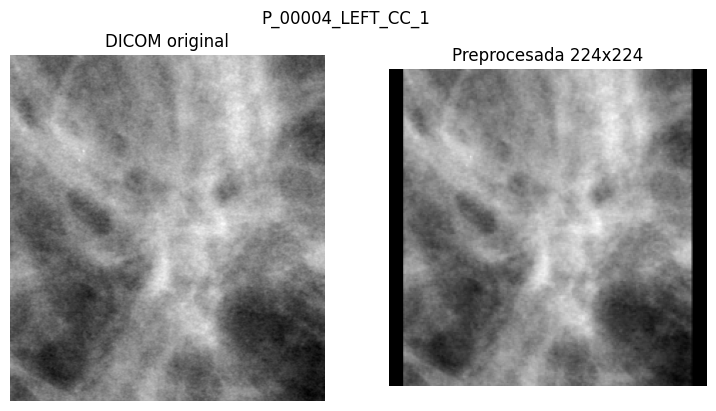

In [4]:
LESION = parts["train"].lesion_id.iloc[0]      # cambia por cualquier lesion_id

ruta = disp.set_index("lesion_id").loc[LESION, "crop_path"]
ds = pydicom.dcmread(ruta)
print("PatientID DICOM:", ds.PatientID, "| SeriesDescription:", ds.get("SeriesDescription"))
print("Tamaño original:", ds.pixel_array.shape, ds.pixel_array.dtype,
      "| fotometría:", ds.get("PhotometricInterpretation"))
fig, ax = plt.subplots(1, 2, figsize=(9, 4.5))
ax[0].imshow(ds.pixel_array, cmap="gray"); ax[0].set_title("DICOM original")
ax[1].imshow(Image.open(f"{PNG}/{LESION}.png"), cmap="gray"); ax[1].set_title("Preprocesada 224x224")
for a in ax: a.axis("off")
plt.suptitle(LESION); plt.show()

## 2. Distribución por clases

label  benigna  maligna  All  % malignas
split                                   
test        17       11   28        39.3
train       82       64  146        43.8
val         27       10   37        27.0
All        126       85  211        40.3


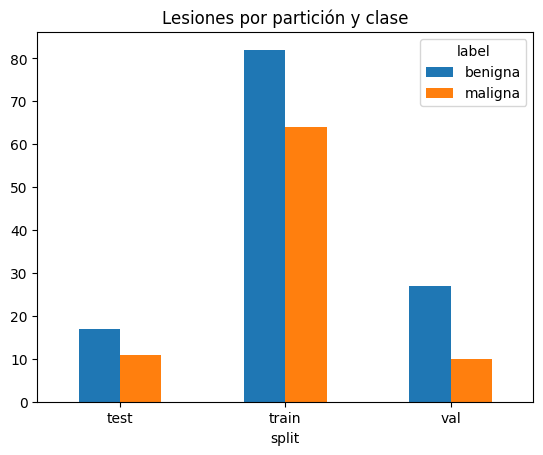

In [5]:
tabla = pd.crosstab(todas.split, todas.label.map({0: "benigna", 1: "maligna"}), margins=True)
tabla["% malignas"] = (100 * tabla["maligna"] / tabla["All"]).round(1)
print(tabla)
tabla.drop(index="All")[["benigna", "maligna"]].plot.bar(rot=0, title="Lesiones por partición y clase")
plt.show()

## 3. Ningún paciente en más de una partición

In [6]:
pac = {s: set(d.patient_id) for s, d in parts.items()}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    comunes = pac[a] & pac[b]
    print(f"{a} y {b}: {len(comunes)} pacientes", sorted(comunes))
    assert not comunes
print("Pacientes por partición:", {s: len(p) for s, p in pac.items()})

# Ejemplo: la paciente con más lesiones y en qué partición quedaron todas
p_max = todas.patient_id.value_counts().idxmax()
print(todas[todas.patient_id == p_max][["lesion_id", "label", "split"]].to_string(index=False))

train y val: 0 pacientes []
train y test: 0 pacientes []
val y test: 0 pacientes []
Pacientes por partición: {'train': 74, 'val': 16, 'test': 15}
          lesion_id  label split
  P_00419_LEFT_CC_1      0 train
  P_00419_LEFT_CC_2      1 train
 P_00419_LEFT_MLO_1      1 train
 P_00419_LEFT_MLO_2      0 train
 P_00419_RIGHT_CC_1      0 train
P_00419_RIGHT_MLO_1      0 train


## 4. Revisar identificadores

In [7]:
N_REVISAR = 10       # cuántas lesiones al azar se comparan con el encabezado DICOM

# lesion_id = patient_id + mama + vista + abnormality id
reconstruido = (todas.patient_id + "_" + todas["left or right breast"] + "_"
                + todas["image view"] + "_" + todas["abnormality id"].astype(str))
print("lesion_id único:", todas.lesion_id.is_unique,
      "| coincide con su reconstrucción:", bool((reconstruido == todas.lesion_id).all()))

m = todas.sample(N_REVISAR, random_state=None).merge(disp[["lesion_id", "crop_path"]], on="lesion_id")
m["pid_dicom"] = [str(pydicom.dcmread(r, stop_before_pixels=True).PatientID) for r in m.crop_path]
m["coincide"] = m.pid_dicom.str.split("_", n=1).str[1] == m.lesion_id
print(m[["lesion_id", "pid_dicom", "split", "coincide"]].to_string(index=False))

lesion_id único: True | coincide con su reconstrucción: True
          lesion_id                         pid_dicom split  coincide
P_00417_RIGHT_MLO_1 Mass-Training_P_00417_RIGHT_MLO_1   val      True
 P_00419_LEFT_MLO_1  Mass-Training_P_00419_LEFT_MLO_1 train      True
 P_00437_LEFT_MLO_1  Mass-Training_P_00437_LEFT_MLO_1 train      True
 P_00016_LEFT_MLO_1      Mass-Test_P_00016_LEFT_MLO_1   val      True
P_00375_RIGHT_MLO_1     Mass-Test_P_00375_RIGHT_MLO_1 train      True
 P_00411_RIGHT_CC_1  Mass-Training_P_00411_RIGHT_CC_1 train      True
P_00023_RIGHT_MLO_1 Mass-Training_P_00023_RIGHT_MLO_1   val      True
 P_00044_RIGHT_CC_3  Mass-Training_P_00044_RIGHT_CC_3   val      True
 P_00051_LEFT_MLO_1  Mass-Training_P_00051_LEFT_MLO_1 train      True
  P_00016_LEFT_CC_1       Mass-Test_P_00016_LEFT_CC_1   val      True


## 5. Entrenamiento preliminar (historial guardado por el notebook 05)

           fecha   modelo  semilla  epocas  mejor_epoca  batch optimizador     lr          aumentos  tiempo_s      gpu  auc_val auc_val_ic95
2026-11-17 20:17 baseline       42      30            3     16        Adam 0.0010 flip=True, rot=10      73.9 Tesla T4    0.648    0.47-0.82
2026-11-17 20:18 resnet18       42      20            9     16        Adam 0.0001 flip=True, rot=10      36.0 Tesla T4    0.819    0.63-0.99


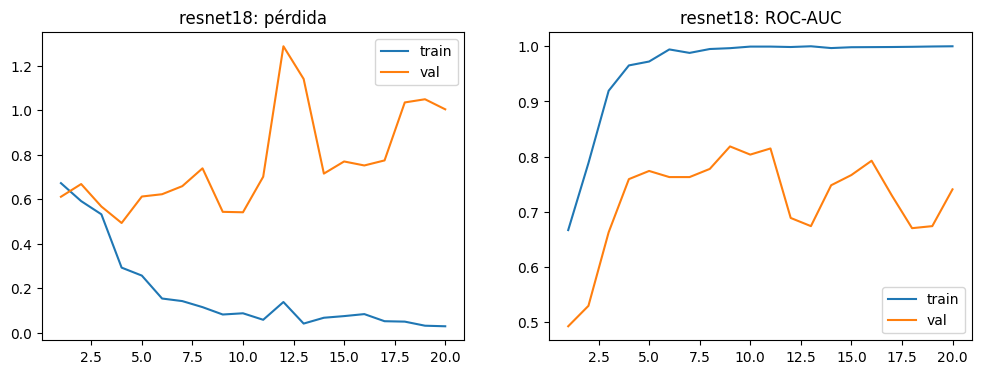

Mejor época por AUC de validación: 9 | AUC val: 0.819


In [8]:
MODELO = "resnet18"     # o "baseline"

h = pd.read_csv(f"{RES}/historial_{MODELO}.csv")
print(pd.read_csv(f"{RES}/registro_experimentos.csv").to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h.epoca, h.loss_train, label="train"); ax[0].plot(h.epoca, h.loss_val, label="val")
ax[0].set_title(f"{MODELO}: pérdida"); ax[0].legend()
ax[1].plot(h.epoca, h.auc_train, label="train"); ax[1].plot(h.epoca, h.auc_val, label="val")
ax[1].set_title(f"{MODELO}: ROC-AUC"); ax[1].legend()
plt.show()
print("Mejor época por AUC de validación:", int(h.auc_val.idxmax()) + 1,
      "| AUC val:", round(h.auc_val.max(), 3))

## 6. Cambiar el umbral (solo validación)

In [9]:
UMBRAL = 0.5        # <- el docente puede pedir 0.3, 0.4, ...

pred = pd.read_csv(f"{RES}/pred_val_{MODELO}.csv")
r = mu.metricas(pred.label, pred.score, UMBRAL)
print(pd.Series(r).to_string())
print("\nMatriz de confusión (filas = real, columnas = predicho)")
print(pd.DataFrame([[r["TN"], r["FP"]], [r["FN"], r["TP"]]],
                   index=["real benigna", "real maligna"], columns=["pred benigna", "pred maligna"]))

umbral                 0.5
TP                       6
FN                       4
TN                      19
FP                       8
sensibilidad           0.6
sens_ic95        0.31-0.83
especificidad     0.703704
esp_ic95         0.52-0.84
precision         0.428571
f1                     0.5

Matriz de confusión (filas = real, columnas = predicho)
              pred benigna  pred maligna
real benigna            19             8
real maligna             4             6


## 7. Localizar un falso negativo

Falsos negativos con umbral 0.5: 4
         lesion_id patient_id  label    score
 P_00198_LEFT_CC_1    P_00198      1 0.129288
P_00396_LEFT_MLO_1    P_00396      1 0.149555
P_00198_LEFT_MLO_1    P_00198      1 0.246195
P_00324_RIGHT_CC_1    P_00324      1 0.357272


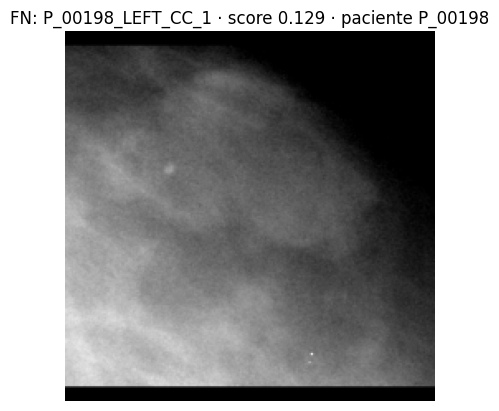

In [10]:
fn = pred[(pred.label == 1) & (pred.score < UMBRAL)].sort_values("score")
print(f"Falsos negativos con umbral {UMBRAL}: {len(fn)}")
print(fn.to_string(index=False))
if len(fn):
    r = fn.iloc[0]   # el más "seguro" de ser benigno siendo maligno
    plt.imshow(Image.open(f"{PNG}/{r.lesion_id}.png"), cmap="gray")
    plt.title(f"FN: {r.lesion_id} · score {r.score:.3f} · paciente {r.patient_id}")
    plt.axis("off"); plt.show()

## 8. Alterar una transformación
Se muestran 6 versiones aumentadas de una imagen de entrenamiento. Validación y prueba
**no** llevan aumentos. Para cambiar la transformación: edita `FLIP` y `ROTACION`.
Si se pide reentrenar con la nueva transformación, pon `REENTRENAR = True` (pocas épocas, solo
para ver el efecto; no sobrescribe el checkpoint del notebook 05).

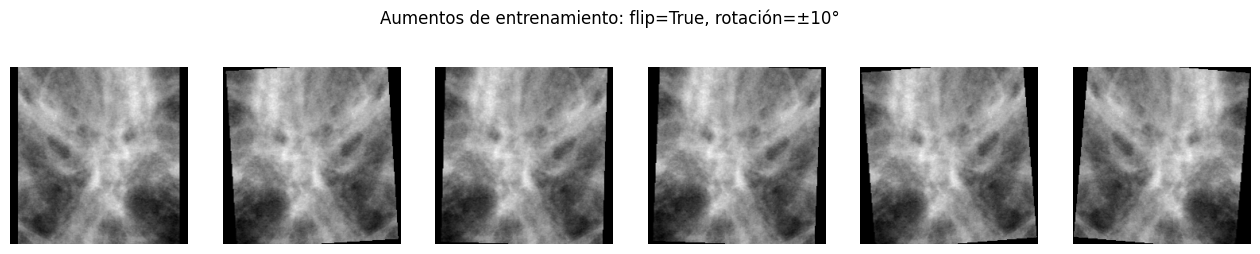

In [11]:
FLIP, ROTACION = True, 10       # p. ej. ROTACION = 30 o FLIP = False
REENTRENAR, EPOCAS_DEMO = False, 5

t = mu.transformaciones(entrenamiento=True, flip=FLIP, rotacion=ROTACION)
img = Image.open(f"{PNG}/{LESION}.png").convert("RGB")
fig, ax = plt.subplots(1, 6, figsize=(16, 3))
media, std = np.array(mu.MEDIA_IMAGENET), np.array(mu.STD_IMAGENET)
for a in ax:
    x = t(img).permute(1, 2, 0).numpy() * std + media   # deshacer la normalización para verla
    a.imshow(np.clip(x, 0, 1)); a.axis("off")
plt.suptitle(f"Aumentos de entrenamiento: flip={FLIP}, rotación=±{ROTACION}°"); plt.show()

if REENTRENAR:
    mu.fijar_semilla(42)
    disp_ = "cuda" if torch.cuda.is_available() else "cpu"
    tr, va = parts["train"], parts["val"]
    h_demo, ep, seg = mu.entrenar(
        mu.crear_modelo(MODELO),
        mu.crear_loader(tr, PNG, True, 16, 42, FLIP, ROTACION),
        mu.crear_loader(tr, PNG, False, 16, 42),
        mu.crear_loader(va, PNG, False, 16, 42),
        EPOCAS_DEMO, 1e-4 if MODELO == "resnet18" else 1e-3, disp_, "/content/demo.pt")
    print(f"Mejor época {ep} | {seg:.0f} s")